# 6. Evaluación estadística

En este capítulo evaluamos todos los modelos en el conjunto de prueba (día 30 completo) con métricas de discriminación, probabilísticas, de umbral fijo y de utilidad de negocio, y contrastamos las diferencias con pruebas estadísticas. Aquí respondemos la pregunta P3: si el MLP mejora de forma significativa a las líneas base.

| § | Contenido | Método |
|---|---|---|
| 6.1 | Tabla de métricas | Media ± DE e IC 95 % $t$ entre semillas |
| 6.2 | Discriminación | Curvas ROC y PR |
| 6.3 | Calibración | Curva de calibración y ECE |
| 6.4 | Umbral fijo | Umbral elegido en validación, matriz de confusión |
| 6.5 | Utilidad de negocio | Lift por decil y ganancia acumulada |
| 6.6 | Inferencia | Bootstrap, DeLong, McNemar, $t$ pareada con Holm |
| 6.7 | Ponderación de clases | MLP con y sin pesos por clase |

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import config as C
from src import plots as P
from src import report as R
from src.persist import load_json

P.setup()
C.ensure_dirs()
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 90)
print("Resultados:", C.RESULTS.relative_to(C.ROOT), "| prueba de humo:", C.SMOKE)

from sklearn.metrics import precision_recall_curve, roc_curve
from src import metrics as M

y = R.y_split("test")
yv = R.y_split("val")
enc = R.runs("scikit-learn", "encoding")
best_enc = enc.groupby("encoding")["val.roc_auc"].mean().idxmax()
sk = pd.concat([enc[enc["encoding"].isin([best_enc, C.MLP_TUNE_ENCODING, "freq"])], R.runs("scikit-learn", "baselines")])
sk = sk.drop_duplicates("run_dir")
spk = R.runs("PySpark", "main")
todos = pd.concat([sk, spk], ignore_index=True)
todos["modelo"] = todos.apply(R.label, axis=1)
todos["grupo"] = todos["env"] + " · " + todos["size"].astype(str)
print(f"Prueba: {R.num(len(y))} impresiones, tasa de clics {R.pct(y.mean(), 2)} | mejor codificación en validación: {C.ENCODING_LABELS[best_enc]}")

Resultados: results | prueba de humo: False


Prueba: 4 218 938 impresiones, tasa de clics 16.93 % | mejor codificación en validación: Hashing 2^14


## 6.1 Tabla de métricas

Para cada modelo reportamos media ± desviación estándar entre semillas y, entre corchetes, el intervalo de confianza del 95 % para la media, $\bar x \pm t_{0.975,\,R-1}\, s / \sqrt{R}$. El umbral de las métricas de umbral fijo se eligió en validación para cada corrida.

Las métricas probabilísticas son:

- **Log loss:** $-\frac{1}{N}\sum_i [y_i \log p_i + (1 - y_i)\log(1 - p_i)]$, penaliza las probabilidades confiadas y equivocadas.
- **Brier:** $\frac{1}{N}\sum_i (p_i - y_i)^2$, el error cuadrático de la probabilidad.
- **ECE:** $\sum_{b=1}^{15} \frac{|B_b|}{N} \big| \bar y_{B_b} - \bar p_{B_b} \big|$, con 15 contenedores de igual frecuencia; mide la distancia media entre la probabilidad predicha y la frecuencia observada de clics (Guo et al., 2017). Usamos contenedores de igual frecuencia porque la mayoría de las probabilidades se concentra por debajo de 0.3.

In [2]:
mets = ["test.roc_auc", "test.pr_auc", "test.log_loss", "test.brier", "test.ece", "test.accuracy", "test.precision", "test.recall", "test.f1"]
s61 = R.summarize(todos, ["grupo", "modelo"], mets)
t61 = R.pretty(s61, ["grupo", "modelo"], mets, ci=False)
display(t61.set_index(["grupo", "modelo"]))
ci = R.pretty(s61, ["grupo", "modelo"], ["test.roc_auc", "test.log_loss", "test.ece"])
display(ci.set_index(["grupo", "modelo"]).drop(columns="semillas"))
s61.to_csv(C.SUMMARY / "tabla_6_1.csv", index=False)

semillas  \
grupo             modelo                                         
scikit-learn · 1M MLP · Frecuencia                           5   
                  MLP · Hashing 2^14                         5   
                  Gradient boosting · Frecuencia             5   
                  Regresión logística · Frecuencia           5   
                  Regresión logística · Hashing 2^14         5   
PySpark · 100k    Regresión logística · Hashing 2^12         1   
                  MLP · Hashing 2^12                         1   

                                                              ROC AUC  \
grupo             modelo                                                
scikit-learn · 1M MLP · Frecuencia                    0.6632 ± 0.0121   
                  MLP · Hashing 2^14                  0.7315 ± 0.0014   
                  Gradient boosting · Frecuencia      0.7246 ± 0.0011   
                  Regresión logística · Frecuencia    0.6777 ± 0.0024   
                  Regresión logística · Hashing 2^14  0.7273 ± 0.0019   
PySpark · 100k    Regresión logística · Hashing 2^12  0.7140 ± 0.0000   
                  MLP · Hashing 2^12                  0.7109 ± 0.0000   

                                                               PR AUC  \
grupo             modelo                                                
scikit-learn · 1M MLP · Frecuencia                    0.3036 ± 0.0115   
                  MLP · Hashing 2^14                  0.3606 ± 0.0013   
                  Gradient boosting · Frecuencia      0.3500 ± 0.0011   
                  Regresión logística · Frecuencia    0.2976 ± 0.0012   
                  Regresión logística · Hashing 2^14  0.3518 ± 0.0017   
PySpark · 100k    Regresión logística · Hashing 2^12  0.3276 ± 0.0000   
                  MLP · Hashing 2^12                  0.3275 ± 0.0000   

                                                             Log loss  \
grupo             modelo                                                
scikit-learn · 1M MLP · Frecuencia                    0.4320 ± 0.0042   
                  MLP · Hashing 2^14                  0.4055 ± 0.0005   
                  Gradient boosting · Frecuencia      0.4085 ± 0.0005   
                  Regresión logística · Frecuencia    0.4285 ± 0.0013   
                  Regresión logística · Hashing 2^14  0.4084 ± 0.0019   
PySpark · 100k    Regresión logística · Hashing 2^12  0.4175 ± 0.0000   
                  MLP · Hashing 2^12                  0.4155 ± 0.0000   

                                                                Brier  \
grupo             modelo                                                
scikit-learn · 1M MLP · Frecuencia                    0.1338 ± 0.0018   
                  MLP · Hashing 2^14                  0.1262 ± 0.0001   
                  Gradient boosting · Frecuencia      0.1270 ± 0.0001   
                  Regresión logística · Frecuencia    0.1331 ± 0.0004   
                  Regresión logística · Hashing 2^14  0.1272 ± 0.0006   
PySpark · 100k    Regresión logística · Hashing 2^12  0.1304 ± 0.0000   
                  MLP · Hashing 2^12                  0.1293 ± 0.0000   

                                                                  ECE  \
grupo             modelo                                                
scikit-learn · 1M MLP · Frecuencia                    0.0286 ± 0.0100   
                  MLP · Hashing 2^14                  0.0117 ± 0.0024   
                  Gradient boosting · Frecuencia      0.0131 ± 0.0012   
                  Regresión logística · Frecuencia    0.0231 ± 0.0043   
                  Regresión logística · Hashing 2^14  0.0175 ± 0.0109   
PySpark · 100k    Regresión logística · Hashing 2^12  0.0277 ± 0.0000   
                  MLP · Hashing 2^12                  0.0128 ± 0.0000   

                                                             Accuracy  \
grupo             modelo                                                
scikit-learn · 1M MLP ·

ROC AUC  \
grupo             modelo                                                                 
scikit-learn · 1M MLP · Frecuencia                    0.6632 ± 0.0121 [0.6482, 0.6783]   
                  MLP · Hashing 2^14                  0.7315 ± 0.0014 [0.7297, 0.7333]   
                  Gradient boosting · Frecuencia      0.7246 ± 0.0011 [0.7232, 0.7260]   
                  Regresión logística · Frecuencia    0.6777 ± 0.0024 [0.6747, 0.6807]   
                  Regresión logística · Hashing 2^14  0.7273 ± 0.0019 [0.7250, 0.7296]   
PySpark · 100k    Regresión logística · Hashing 2^12                   0.7140 ± 0.0000   
                  MLP · Hashing 2^12                                   0.7109 ± 0.0000   

                                                                              Log loss  \
grupo             modelo                                                                 
scikit-learn · 1M MLP · Frecuencia                    0.4320 ± 0.0042 [0.4268, 0.4373]   
                  MLP · Hashing 2^14                  0.4055 ± 0.0005 [0.4048, 0.4062]   
                  Gradient boosting · Frecuencia      0.4085 ± 0.0005 [0.4079, 0.4091]   
                  Regresión logística · Frecuencia    0.4285 ± 0.0013 [0.4269, 0.4301]   
                  Regresión logística · Hashing 2^14  0.4084 ± 0.0019 [0.4060, 0.4107]   
PySpark · 100k    Regresión logística · Hashing 2^12                   0.4175 ± 0.0000   
                  MLP · Hashing 2^12                                   0.4155 ± 0.0000   

                                                                                   ECE  
grupo             modelo                                                                
scikit-learn · 1M MLP · Frecuencia                    0.0286 ± 0.0100 [0.0162, 0.0411]  
                  MLP · Hashing 2^14                  0.0117 ± 0.0024 [0.0087, 0.0147]  
                  Gradient boosting · Frecuencia      0.0131 ± 0.0012 [0.0115, 0.0146]  
                  Regresión logística · Frecuencia    0.0231 ± 0.0043 [0.0178, 0.0284]  
                  Regresión logística · Hashing 2^14  0.0175 ± 0.0109 [0.0040, 0.0311]  
PySpark · 100k    Regresión logística · Hashing 2^12                   0.0277 ± 0.0000  
                  MLP · Hashing 2^12                                   0.0128 ± 0.0000

## 6.2 Curvas ROC y PR

Superponemos las curvas de la semilla mediana (por ROC AUC) de cada modelo. En la curva PR, la línea horizontal es la tasa de clics del día de prueba, el valor de un clasificador aleatorio.

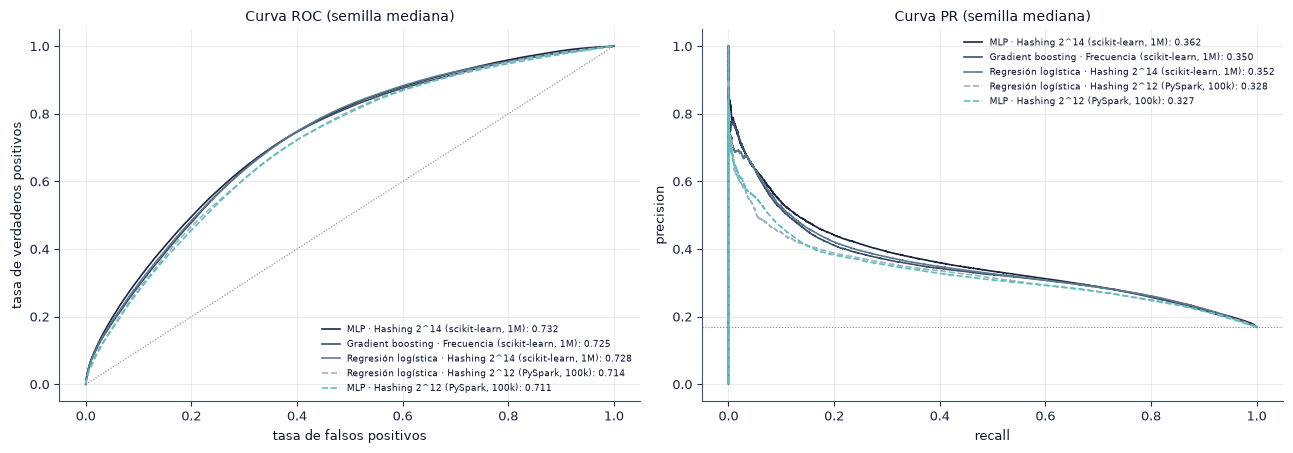

In [3]:
# Curvas: MLP con la codificación elegida y líneas base principales de scikit-learn, y todos los modelos de Spark.
clave = (todos["env"] == "PySpark") | ((todos["model"] == "mlp") & (todos["encoding"] == best_enc)) | \
        ((todos["model"] == "lr") & (todos["encoding"] == C.MLP_TUNE_ENCODING)) | (todos["model"] == "hgb")
sel = []
for (gname, mname), g in todos[clave].groupby(["grupo", "modelo"], sort=False):
    r = R.median_seed(g)
    p = R.preds(r)
    if p is not None:
        sel.append((f"{mname} ({gname.split(' · ')[0]}, {gname.split(' · ')[1]})", r, p))
pal = ["#1C2541", "#3A506B", "#5C7A8C", "#9DB4C0", "#5BC0BE", "#C8553D", "#E0A458", "#7A9E7E", "#8E7DBE", "#444444", "#B5838D", "#6D6875"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for (name, r, p), cc in zip(sel, pal):
    ls = "-" if r["env"] == "scikit-learn" else "--"
    f, t, _ = roc_curve(y, p); axes[0].plot(f, t, color=cc, ls=ls, lw=1.2, label=f"{name}: {r['test.roc_auc']:.3f}")
    pr, rc, _ = precision_recall_curve(y, p); axes[1].plot(rc, pr, color=cc, ls=ls, lw=1.2, label=f"{name}: {r['test.pr_auc']:.3f}")
axes[0].plot([0, 1], [0, 1], c="gray", lw=0.8, ls=":"); axes[0].set_xlabel("tasa de falsos positivos"); axes[0].set_ylabel("tasa de verdaderos positivos")
axes[0].set_title("Curva ROC (semilla mediana)"); axes[0].legend(fontsize=6.5, loc="lower right")
axes[1].axhline(y.mean(), c="gray", lw=0.8, ls=":"); axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")
axes[1].set_title("Curva PR (semilla mediana)"); axes[1].legend(fontsize=6.5, loc="upper right")
fig.tight_layout(); P.save(fig, "6_2_roc_pr"); plt.show()

## 6.3 Calibración

Una probabilidad está calibrada si, entre las impresiones a las que el modelo asigna una probabilidad cercana a $p$, la fracción de clics es cercana a $p$. La curva de calibración grafica la probabilidad media predicha contra la frecuencia observada en cada contenedor; la diagonal es la calibración perfecta.

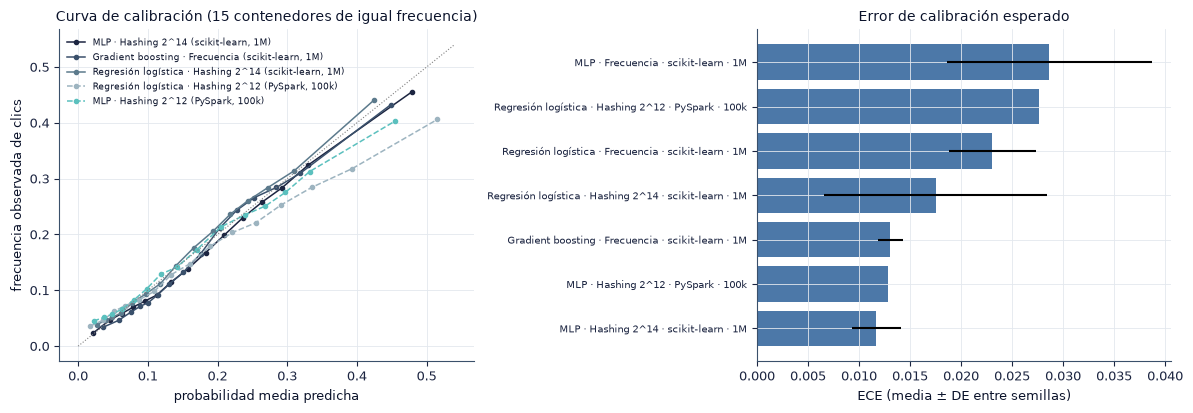

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for (name, r, p), cc in zip(sel, pal):
    ls = "-" if r["env"] == "scikit-learn" else "--"
    mp, fo = M.calibration_points(y, p)
    axes[0].plot(mp, fo, marker="o", ms=3, color=cc, ls=ls, lw=1.1, label=name)
lim = max(axes[0].get_xlim()[1], axes[0].get_ylim()[1])
axes[0].plot([0, lim], [0, lim], c="gray", lw=0.8, ls=":"); axes[0].set_xlabel("probabilidad media predicha"); axes[0].set_ylabel("frecuencia observada de clics")
axes[0].set_title("Curva de calibración (15 contenedores de igual frecuencia)"); axes[0].legend(fontsize=6.5)
e = s61.sort_values("test.ece|media")
axes[1].barh(e["modelo"] + " · " + e["grupo"], e["test.ece|media"], xerr=e["test.ece|de"], color=C.BAR)
axes[1].set_xlabel("ECE (media ± DE entre semillas)"); axes[1].set_title("Error de calibración esperado"); axes[1].tick_params(axis="y", labelsize=7)
fig.tight_layout(); P.save(fig, "6_3_calibracion"); plt.show()

In [5]:
mejor_cal = e.iloc[0]
peor_cal = e.iloc[-1]
sesgo = todos.groupby(["grupo", "modelo"])["test.mean_pred"].mean() - y.mean()
R.findings(
    f"El modelo mejor calibrado es {mejor_cal['modelo']} ({mejor_cal['grupo']}), con ECE {mejor_cal['test.ece|media']:.4f}; el peor es "
    f"{peor_cal['modelo']} ({peor_cal['grupo']}), con {peor_cal['test.ece|media']:.4f}. La tasa de clics del día de prueba es {R.pct(y.mean(), 2)}; "
    f"la probabilidad media predicha se desvía de ella entre {sesgo.min():+.4f} y {sesgo.max():+.4f} según el modelo.",
    {"Preprocesamiento": "ninguna transformación usa la etiqueta del día de prueba, por lo que la diferencia entre la probabilidad media y la tasa observada refleja la deriva del CTR entre días.",
     "Modelado": "si un sistema de pujas usara estas probabilidades, convendría recalibrarlas con el día más reciente disponible (por ejemplo, con regresión isotónica sobre validación).",
     "Riesgos": "el ECE depende del número y del tipo de contenedores; lo complementamos con el log loss y el Brier, que no dependen de esa elección."})

### Hallazgos y decisiones

El modelo mejor calibrado es MLP · Hashing 2^14 (scikit-learn · 1M), con ECE 0.0117; el peor es MLP · Frecuencia (scikit-learn · 1M), con 0.0286. La tasa de clics del día de prueba es 16.93 %; la probabilidad media predicha se desvía de ella entre +0.0025 y +0.0217 según el modelo.

- **Preprocesamiento:** ninguna transformación usa la etiqueta del día de prueba, por lo que la diferencia entre la probabilidad media y la tasa observada refleja la deriva del CTR entre días.
- **Modelado:** si un sistema de pujas usara estas probabilidades, convendría recalibrarlas con el día más reciente disponible (por ejemplo, con regresión isotónica sobre validación).
- **Riesgos:** el ECE depende del número y del tipo de contenedores; lo complementamos con el log loss y el Brier, que no dependen de esa elección.


## 6.4 Umbral de decisión y matriz de confusión

El umbral se elige en validación como el que maximiza el F1 y se aplica sin cambios en prueba. Mostramos las matrices de confusión de la semilla mediana del MLP de scikit-learn y del MLP de Spark.

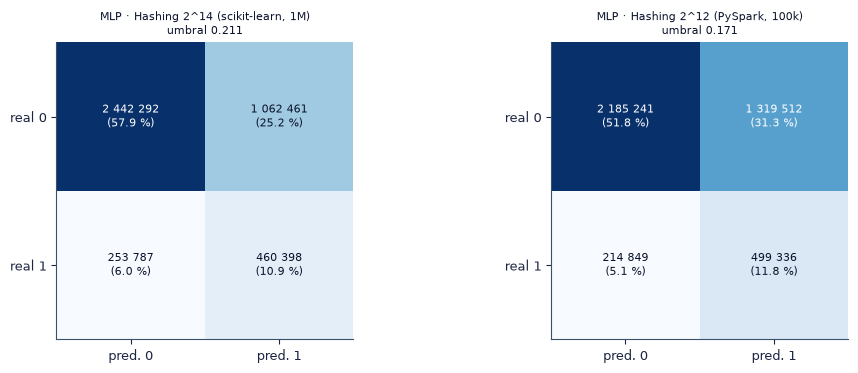

In [6]:
mlps = [(n, r, p) for n, r, p in sel if r["model"] == "mlp" and (r["env"] == "PySpark" or r["encoding"] == best_enc)]
fig, axes = plt.subplots(1, len(mlps), figsize=(5.2 * len(mlps), 3.8), squeeze=False)
for ax, (name, r, p) in zip(axes[0], mlps):
    cm = np.array([[r["test.tn"], r["test.fp"]], [r["test.fn"], r["test.tp"]]])
    ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{R.num(cm[i, j])}\n({100 * cm[i, j] / cm.sum():.1f} %)", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "#0B132B", fontsize=8)
    ax.set_xticks([0, 1], ["pred. 0", "pred. 1"]); ax.set_yticks([0, 1], ["real 0", "real 1"])
    ax.set_title(f"{name}\numbral {r['test.threshold']:.3f}", fontsize=8)
fig.tight_layout(); P.save(fig, "6_4_confusion"); plt.show()

## 6.5 Lift y ganancia acumulada

Si una campaña solo puede mostrar el anuncio a una fracción $q$ de las impresiones, conviene elegir las de mayor probabilidad estimada. La **ganancia acumulada** es la fracción de todos los clics que se capturan con ese $q$ %, y el **lift** de un decil es su CTR dividido entre el CTR global. Un modelo aleatorio tiene ganancia $q$ y lift 1.

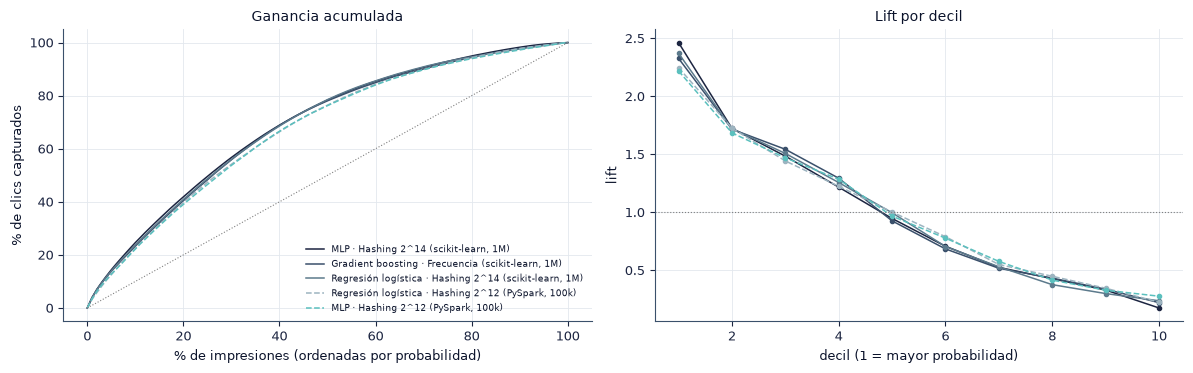

,% de clics en el 20 % superior,lift del primer decil
"MLP · Hashing 2^14 (scikit-learn, 1M)",41.9,2.46
"Regresión logística · Hashing 2^14 (scikit-learn, 1M)",40.9,2.37
"Gradient boosting · Frecuencia (scikit-learn, 1M)",40.4,2.33
"Regresión logística · Hashing 2^12 (PySpark, 100k)",39.7,2.25
"MLP · Hashing 2^12 (PySpark, 100k)",39.0,2.22


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
lifts = {}
for (name, r, p), cc in zip(sel, pal):
    ls = "-" if r["env"] == "scikit-learn" else "--"
    lg = M.lift_gain(y, p)
    axes[0].plot(100 * lg["q"], 100 * lg["gain"], color=cc, ls=ls, lw=1.1, label=name)
    axes[1].plot(np.arange(1, 11), lg["lift_decil"], marker="o", ms=3, color=cc, ls=ls, lw=1.1)
    lifts[name] = lg
axes[0].plot([0, 100], [0, 100], c="gray", ls=":", lw=0.8); axes[0].set_xlabel("% de impresiones (ordenadas por probabilidad)")
axes[0].set_ylabel("% de clics capturados"); axes[0].set_title("Ganancia acumulada"); axes[0].legend(fontsize=6.5)
axes[1].axhline(1, c="gray", ls=":", lw=0.8); axes[1].set_xlabel("decil (1 = mayor probabilidad)"); axes[1].set_ylabel("lift"); axes[1].set_title("Lift por decil")
fig.tight_layout(); P.save(fig, "6_5_lift"); plt.show()
g20 = pd.Series({k: v["gain"][20] for k, v in lifts.items()}).sort_values(ascending=False)
l1 = pd.Series({k: v["lift_decil"][0] for k, v in lifts.items()})
display(pd.DataFrame({"% de clics en el 20 % superior": (100 * g20).round(1), "lift del primer decil": l1[g20.index].round(2)}))

In [8]:
R.findings(
    f"Con el 20 % de impresiones de mayor probabilidad, el mejor modelo ({g20.index[0]}) captura {R.pct(g20.iloc[0])} de los clics y el más débil "
    f"{R.pct(g20.iloc[-1])}; un modelo aleatorio capturaría 20 %. El lift del primer decil va de {l1.min():.2f} a {l1.max():.2f}.",
    {"Preprocesamiento": "las curvas usan la semilla mediana de cada modelo y todo el día de prueba.",
     "Modelado": "las diferencias en ganancia acumulada se concentran en el primer decil, donde el modelo decide qué impresiones priorizar.",
     "Riesgos": "el lift supone que el costo de mostrar el anuncio es igual para todas las impresiones; en una subasta real el costo varía."})

### Hallazgos y decisiones

Con el 20 % de impresiones de mayor probabilidad, el mejor modelo (MLP · Hashing 2^14 (scikit-learn, 1M)) captura 41.9 % de los clics y el más débil 39.0 %; un modelo aleatorio capturaría 20 %. El lift del primer decil va de 2.22 a 2.46.

- **Preprocesamiento:** las curvas usan la semilla mediana de cada modelo y todo el día de prueba.
- **Modelado:** las diferencias en ganancia acumulada se concentran en el primer decil, donde el modelo decide qué impresiones priorizar.
- **Riesgos:** el lift supone que el costo de mostrar el anuncio es igual para todas las impresiones; en una subasta real el costo varía.


## 6.6 Inferencia estadística

Usamos cuatro procedimientos complementarios:

- **Intervalos bootstrap percentil** del ROC AUC de la semilla mediana de cada modelo, con 1000 remuestreos de una submuestra fija de 500 mil impresiones del día de prueba (Efron y Tibshirani, 1993). Reflejan la variación por la muestra de prueba.
- **Prueba de DeLong** para dos AUC medidas sobre las mismas impresiones (DeLong et al., 1988), con el algoritmo rápido de Sun y Xu (2014). La aplicamos semilla por semilla.
- **Prueba de McNemar** sobre las clasificaciones con el umbral de validación (McNemar, 1947): compara cuántas impresiones acierta solo un modelo frente a cuántas acierta solo el otro.
- **Prueba $t$ pareada entre semillas** sobre la diferencia de ROC AUC, con corrección de Holm por las tres comparaciones (Holm, 1979). Refleja la variación por el entrenamiento.

Con millones de impresiones de prueba, DeLong y McNemar detectan diferencias muy pequeñas; por eso exigimos además que la diferencia media alcance $\delta = 0.005$.

In [9]:
boot = []
for name, r, p in sel:
    b = M.bootstrap_ci(y, p)
    boot.append({"modelo": name, "ROC AUC": b["estimate"], "IC bootstrap inf": b["lo"], "IC bootstrap sup": b["hi"]})
boot = pd.DataFrame(boot).set_index("modelo")
display(boot.round(4))

,ROC AUC,IC bootstrap inf,IC bootstrap sup
modelo,,,
"MLP · Hashing 2^14 (scikit-learn, 1M)",0.7325,0.7307,0.7341
"Gradient boosting · Frecuencia (scikit-learn, 1M)",0.7256,0.7237,0.7273
"Regresión logística · Hashing 2^14 (scikit-learn, 1M)",0.7283,0.7266,0.7300
"Regresión logística · Hashing 2^12 (PySpark, 100k)",0.7136,0.7117,0.7153
"MLP · Hashing 2^12 (PySpark, 100k)",0.7112,0.7095,0.7130


In [10]:
mlp = enc[enc["encoding"] == best_enc].set_index("seed")
bases = {"Regresión logística · " + C.ENCODING_LABELS[C.MLP_TUNE_ENCODING]: ("lr", C.MLP_TUNE_ENCODING),
         "Regresión logística · Frecuencia": ("lr", "freq"), "Gradient boosting · Frecuencia": ("hgb", "freq")}
bl = R.runs("scikit-learn", "baselines")
rows, dl, mc = [], [], []
for nombre, (kind, e_) in bases.items():
    b = bl[(bl["model"] == kind) & (bl["encoding"] == e_)].set_index("seed")
    seeds = sorted(set(mlp.index) & set(b.index))
    t = M.paired_t(mlp.loc[seeds, "test.roc_auc"].values, b.loc[seeds, "test.roc_auc"].values)
    rows.append({"comparación": f"MLP ({C.ENCODING_LABELS[best_enc]}) − {nombre}", **t})
    for s in seeds:
        pm, pb = R.preds(mlp.loc[s]), R.preds(b.loc[s])
        d = M.delong_test(y, pm, pb)
        mn = M.mcnemar_test(y, (pm >= mlp.loc[s, "test.threshold"]).astype(int), (pb >= b.loc[s, "test.threshold"]).astype(int))
        dl.append({"comparación": nombre, "semilla": s, "ΔAUC": d["diff"], "z": d["z"], "p DeLong": d["p"]})
        mc.append({"comparación": nombre, "semilla": s, "solo MLP acierta": mn["b_solo_1_acierta"], "solo base acierta": mn["c_solo_2_acierta"], "p McNemar": mn["p"]})
p3 = pd.DataFrame(rows).set_index("comparación")
p3["p Holm"] = M.holm(p3["p"].tolist())
p3["significativa y ≥ δ"] = (p3["p Holm"] < C.ALPHA) & (p3["diff"] >= C.DELTA_AUC)
display(p3.rename(columns={"diff": "ΔAUC medio", "lo": "IC inf", "hi": "IC sup", "n": "semillas"}).round(4))
dl, mc = pd.DataFrame(dl), pd.DataFrame(mc)
res_dl = dl.groupby("comparación").agg(**{"ΔAUC medio": ("ΔAUC", "mean"), "p DeLong máx": ("p DeLong", "max"),
                                         "semillas con p < 0.05": ("p DeLong", lambda s: int((s < C.ALPHA).sum()))})
res_mc = mc.groupby("comparación").agg(**{"p McNemar máx": ("p McNemar", "max"), "semillas con p < 0.05": ("p McNemar", lambda s: int((s < C.ALPHA).sum())),
                                         "solo MLP acierta (media)": ("solo MLP acierta", "mean"), "solo base acierta (media)": ("solo base acierta", "mean")})
display(res_dl.round(5)); display(res_mc.round(5))
p3.to_csv(C.SUMMARY / "p3_pruebas.csv"); dl.to_csv(C.SUMMARY / "p3_delong_por_semilla.csv", index=False); mc.to_csv(C.SUMMARY / "p3_mcnemar_por_semilla.csv", index=False)

,ΔAUC medio,IC inf,IC sup,t,p,semillas,p Holm,significativa y ≥ δ
comparación,,,,,,,,
MLP (Hashing 2^14) − Regresión logística · Hashing 2^14,0.0042,0.0006,0.0078,3.2490,0.0314,5,0.0314,False
MLP (Hashing 2^14) − Regresión logística · Frecuencia,0.0538,0.0493,0.0583,33.3701,0.0000,5,0.0000,True
MLP (Hashing 2^14) − Gradient boosting · Frecuencia,0.0069,0.0053,0.0085,11.8100,0.0003,5,0.0006,True


,ΔAUC medio,p DeLong máx,semillas con p < 0.05
comparación,,,
Gradient boosting · Frecuencia,0.0069,0.0,5
Regresión logística · Frecuencia,0.0538,0.0,5
Regresión logística · Hashing 2^14,0.0042,0.0,5


,p McNemar máx,semillas con p < 0.05,solo MLP acierta (media),solo base acierta (media)
comparación,,,,
Gradient boosting · Frecuencia,0.0,5,272892.2,212358.6
Regresión logística · Frecuencia,0.0,5,548421.4,418605.0
Regresión logística · Hashing 2^14,0.0,5,270294.0,199163.0


In [11]:
gana = p3[p3["significativa y ≥ δ"]]
sig_no_rel = p3[(p3["p Holm"] < C.ALPHA) & (p3["diff"] < C.DELTA_AUC) & (p3["diff"] > 0)]
peor = p3[p3["diff"] < 0]
txt = (f"Frente a {len(p3)} líneas base, el MLP con {C.ENCODING_LABELS[best_enc]} logra una mejora significativa y mayor que δ en "
       f"{len(gana)}" + (f" ({', '.join(i.split(' − ')[1] for i in gana.index)})" if len(gana) else "") + ". ")
if len(sig_no_rel):
    txt += f"Contra {', '.join(i.split(' − ')[1] for i in sig_no_rel.index)} la diferencia es significativa pero menor que δ. "
if len(peor):
    txt += f"Contra {', '.join(i.split(' − ')[1] for i in peor.index)} el MLP obtiene en promedio un AUC menor. "
txt += "Las pruebas de DeLong y McNemar por semilla se resumen en las dos tablas anteriores."
R.findings(txt,
    {"Preprocesamiento": "todas las comparaciones usan las mismas impresiones de prueba en el mismo orden, por lo que las pruebas están pareadas por observación y por semilla.",
     "Modelado": ("rechazamos $H_0$ de P3 frente a " + ", ".join(i.split(" − ")[1] for i in gana.index) + ".") if len(gana) else
                 "no rechazamos $H_0$ de P3 con el criterio declarado: el MLP no supera a todas las líneas base por al menos δ con significancia.",
     "Riesgos": "DeLong y McNemar suponen impresiones independientes; las impresiones de un mismo dispositivo están correlacionadas, por lo que sus valores $p$ son optimistas. La prueba $t$ entre semillas no depende de ese supuesto."})

### Hallazgos y decisiones

Frente a 3 líneas base, el MLP con Hashing 2^14 logra una mejora significativa y mayor que δ en 2 (Regresión logística · Frecuencia, Gradient boosting · Frecuencia). Contra Regresión logística · Hashing 2^14 la diferencia es significativa pero menor que δ. Las pruebas de DeLong y McNemar por semilla se resumen en las dos tablas anteriores.

- **Preprocesamiento:** todas las comparaciones usan las mismas impresiones de prueba en el mismo orden, por lo que las pruebas están pareadas por observación y por semilla.
- **Modelado:** rechazamos $H_0$ de P3 frente a Regresión logística · Frecuencia, Gradient boosting · Frecuencia.
- **Riesgos:** DeLong y McNemar suponen impresiones independientes; las impresiones de un mismo dispositivo están correlacionadas, por lo que sus valores $p$ son optimistas. La prueba $t$ entre semillas no depende de ese supuesto.


**Comparación entre entornos con el mismo modelo.** Con la muestra de 100 mil filas, comparamos semilla por semilla los modelos equivalentes de scikit-learn y Spark (sección 4.1). Si los dos entornos implementan el mismo modelo, sus AUC no deberían diferir en más de $\delta$.

In [12]:
sk_sc = R.runs("scikit-learn", "scale"); sp_sc = R.runs("PySpark", "scale")
rows = []
for kind in ("lr_lbfgs", "mlp_lbfgs"):
    a = sk_sc[(sk_sc["model"] == kind) & (sk_sc["size"] == C.SPARK_MLP_SIZE)].set_index("seed")
    b = sp_sc[(sp_sc["model"] == kind) & (sp_sc["size"] == C.SPARK_MLP_SIZE)].set_index("seed")
    for s in sorted(set(a.index) & set(b.index)):
        pa, pb = R.preds(a.loc[s]), R.preds(b.loc[s])
        if pa is None or pb is None:
            continue
        d = M.delong_test(y, pa, pb)
        rows.append({"modelo": R.label({"model": kind, "encoding": C.P1_ENCODING}), "semilla": s, "AUC scikit-learn": d["auc_1"],
                     "AUC PySpark": d["auc_2"], "Δ (sklearn − Spark)": d["diff"], "p DeLong": d["p"],
                     "correlación de probabilidades": float(np.corrcoef(pa, pb)[0, 1])})
envs = pd.DataFrame(rows)
R.tabla(envs, ["modelo", "semilla"], 4)

*Sin datos: este experimento no se ejecutó dentro del límite de tiempo del cómputo (ver la sección de limitaciones y el anexo de reproducibilidad).*

In [13]:
if len(envs):
    em = envs.groupby("modelo")[["Δ (sklearn − Spark)", "correlación de probabilidades"]].mean()
    txt = " ".join(f"{m}: diferencia media de AUC {r['Δ (sklearn − Spark)']:+.4f} y correlación media de {r['correlación de probabilidades']:.3f} entre las probabilidades de ambos entornos."
                   for m, r in em.iterrows())
    dentro = bool((em["Δ (sklearn − Spark)"].abs() < C.DELTA_AUC).all())
else:
    txt, dentro = "No hay corridas equivalentes completas en ambos entornos.", False
R.findings(txt + (" Las diferencias quedan dentro de ±δ: los dos entornos producen modelos de calidad equivalente." if dentro else
                  " Al menos una diferencia supera δ; la atribuimos a las diferencias de implementación del optimizador y de la función hash."),
    {"Preprocesamiento": "ambos entornos usan las mismas filas y el mismo umbral de raras; solo cambia la función hash.",
     "Modelado": "esta equivalencia es la condición de calidad de P1: el punto de cruce del capítulo 7 compara tiempos de modelos que predicen igual de bien.",
     "Riesgos": "L-BFGS con un número fijo de iteraciones puede detenerse en puntos distintos según la implementación; la correlación entre probabilidades lo cuantifica."})

### Hallazgos y decisiones

No hay corridas equivalentes completas en ambos entornos. Al menos una diferencia supera δ; la atribuimos a las diferencias de implementación del optimizador y de la función hash.

- **Preprocesamiento:** ambos entornos usan las mismas filas y el mismo umbral de raras; solo cambia la función hash.
- **Modelado:** esta equivalencia es la condición de calidad de P1: el punto de cruce del capítulo 7 compara tiempos de modelos que predicen igual de bien.
- **Riesgos:** L-BFGS con un número fijo de iteraciones puede detenerse en puntos distintos según la implementación; la correlación entre probabilidades lo cuantifica.


## 6.7 Ponderación de clases

La guía pide reportar métricas con y sin ponderación. Entrenamos el MLP con pesos $w_k = N / (2 N_k)$, que equilibran la contribución de clics y no clics a la pérdida, con la misma codificación y las mismas semillas.

In [14]:
w = R.runs("scikit-learn", "ablation_weight")
base_w = enc[enc["encoding"] == best_enc]
cmp = pd.concat([base_w.assign(ponderación="sin pesos"), w.assign(ponderación="con pesos por clase")])
mets_w = ["test.roc_auc", "test.pr_auc", "test.log_loss", "test.ece", "test.mean_pred", "test.threshold", "test.precision", "test.recall", "test.f1"]
sw = R.summarize(cmp, ["ponderación"], mets_w)
display(R.pretty(sw, ["ponderación"], mets_w, ci=False).rename(columns={"test.mean_pred": "probabilidad media", "test.threshold": "umbral"}).set_index("ponderación"))

,semillas,ROC AUC,PR AUC,Log loss,ECE,probabilidad media,umbral,Precision,Recall,F1
ponderación,,,,,,,,,,
sin pesos,5,0.7315 ± 0.0014,0.3606 ± 0.0013,0.4055 ± 0.0005,0.0117 ± 0.0024,0.1785 ± 0.0049,0.2137 ± 0.0071,0.3049 ± 0.0038,0.6366 ± 0.0201,0.4122 ± 0.0013
con pesos por clase,1,0.7334 ± 0.0000,0.3600 ± 0.0000,0.6197 ± 0.0000,0.2875 ± 0.0000,0.4568 ± 0.0000,0.5685 ± 0.0000,0.3046 ± 0.0000,0.6490 ± 0.0000,0.4146 ± 0.0000


In [15]:
a, b = sw.set_index("ponderación").loc["sin pesos"], sw.set_index("ponderación").loc["con pesos por clase"]
R.findings(
    f"Con pesos por clase, el ROC AUC cambia en {b['test.roc_auc|media'] - a['test.roc_auc|media']:+.4f}, mientras la probabilidad media "
    f"pasa de {a['test.mean_pred|media']:.3f} a {b['test.mean_pred|media']:.3f} y el ECE de {a['test.ece|media']:.3f} a {b['test.ece|media']:.3f}. "
    f"El F1 con umbral de validación cambia en {b['test.f1|media'] - a['test.f1|media']:+.4f}.",
    {"Preprocesamiento": "los pesos se calculan con la tasa de clics de la muestra de entrenamiento.",
     "Modelado": ("la ponderación " + ("eleva" if b["test.mean_pred|media"] > a["test.mean_pred|media"] else "modifica")
                  + " las probabilidades predichas " + ("sin cambiar el ordenamiento de forma relevante (|ΔAUC| < δ)" if abs(b["test.roc_auc|media"] - a["test.roc_auc|media"]) < C.DELTA_AUC else "y cambia el ordenamiento en más de δ")
                  + ("; como el umbral se elige en validación, el F1 apenas cambia" if abs(b["test.f1|media"] - a["test.f1|media"]) < 0.01 else "")
                  + ". Para estimar probabilidades " + ("preferimos entrenar sin pesos." if b["test.ece|media"] > a["test.ece|media"] else "la ponderación no empeora la calibración en este caso.")),
     "Riesgos": "un sistema que use las probabilidades ponderadas sin corregirlas sobreestimaría el CTR esperado de cada impresión."})

### Hallazgos y decisiones

Con pesos por clase, el ROC AUC cambia en +0.0019, mientras la probabilidad media pasa de 0.178 a 0.457 y el ECE de 0.012 a 0.287. El F1 con umbral de validación cambia en +0.0025.

- **Preprocesamiento:** los pesos se calculan con la tasa de clics de la muestra de entrenamiento.
- **Modelado:** la ponderación eleva las probabilidades predichas sin cambiar el ordenamiento de forma relevante (|ΔAUC| < δ); como el umbral se elige en validación, el F1 apenas cambia. Para estimar probabilidades preferimos entrenar sin pesos.
- **Riesgos:** un sistema que use las probabilidades ponderadas sin corregirlas sobreestimaría el CTR esperado de cada impresión.
